# Notebook 03 — Text Preprocessing and Task Preparation

This notebook continues from `02_build_cohort.ipynb`. It validates the master
older-adult cohort, performs a reproducible text and leakage audit, and creates
the depression and anxiety binary-classification datasets.

The notebook deliberately does **not** apply a transformer tokenizer. Exact
tokenisation, chunking, padding and attention-mask creation belong in each
model-specific notebook.

## Main outputs

- `depression_dataset.parquet`
- `depression_dataset_masked.parquet`
- `anxiety_dataset.parquet`
- `anxiety_dataset_masked.parquet`
- aggregate preprocessing and leakage audit files

The same patient-level split created in Notebook 02 is preserved in every
output.


## Methodological decisions used in this notebook

1. **Depression task:** depression-positive admissions versus admissions
   negative for both depression and anxiety.
2. **Anxiety task:** anxiety-positive admissions versus admissions negative
   for both conditions.
3. Admissions positive for both conditions are positive in both relevant
   tasks.
4. Anxiety-only admissions are excluded from depression controls.
5. Depression-only admissions are excluded from anxiety controls.
6. Masked variants replace explicit terms for **both** conditions with
   `[MASK]`.
7. Exact duplicate text is audited but not automatically deleted.
8. Empty text is removed. Very short text is flagged but retained by default.

## 1. Import libraries


This notebook requires `pandas`, `numpy` and `pyarrow`. If `pyarrow` is not
installed in the active Jupyter environment, run the following command in a
temporary notebook cell, restart the kernel, and then run this notebook from
the beginning:

```python
%pip install pyarrow
```


In [21]:
# ============================================================
# CELL 1 - IMPORT LIBRARIES
# ============================================================

from pathlib import Path
from collections import defaultdict
import gc
import hashlib
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow as pa
import pyarrow.parquet as pq

from IPython.display import display


pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)


sns.set_theme(style="whitegrid")


## 2. Configure project paths and preprocessing settings

Place this notebook inside the project repository. The project root is located
automatically, so no team member's username or absolute machine path is
required.

For a smoke-cohort test, set `COHORT_FOLDER_NAME` to
`"cohort_output_smoke"`. For final task datasets, use the complete
`"cohort_output"` folder.


In [22]:
# ============================================================
# CELL 2 - CONFIGURE PATHS AND SETTINGS
# ============================================================

def find_project_root(starting_path):
    starting_path = Path(starting_path).expanduser().resolve()

    for location in [starting_path, *starting_path.parents]:
        if (location / ".git").exists() or (location / "dataset").exists():
            return location

    raise FileNotFoundError(
        "Could not locate the project root. Open Jupyter from inside "
        "the project repository."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
DATASET_DIR = PROJECT_ROOT / "dataset"


# Use "cohort_output_smoke" while testing Notebook 03.
# Change to "cohort_output" for the final complete cohort.
COHORT_FOLDER_NAME = "cohort_output"


COHORT_DIR = DATASET_DIR / COHORT_FOLDER_NAME
COHORT_PATH = COHORT_DIR / "cohort.parquet"
SPLITS_PATH = COHORT_DIR / "splits.parquet"


MODEL_DATASET_DIR = DATASET_DIR / "model_datasets"
AUDIT_DIR = MODEL_DATASET_DIR / "audit_outputs"


MODEL_DATASET_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_DIR.mkdir(parents=True, exist_ok=True)


# Processing settings
BATCH_SIZE = 2_000
MINIMUM_AGE = 60
MINIMUM_WORDS_FOR_SHORT_FLAG = 20
DROP_SHORT_NOTES = False
MASK_REPLACEMENT = "[MASK]"
SAVE_MASKED_VARIANTS = True
NORMALISE_VALIDATION_NAME = True


configuration = pd.DataFrame(
    {
        "setting": [
            "Project root",
            "Master cohort",
            "Patient splits",
            "Output directory",
            "Batch size",
            "Minimum age",
            "Short-note threshold",
            "Drop short notes",
            "Save masked variants",
            "Mask replacement",
        ],
        "value": [
            PROJECT_ROOT,
            COHORT_PATH,
            SPLITS_PATH,
            MODEL_DATASET_DIR,
            BATCH_SIZE,
            MINIMUM_AGE,
            MINIMUM_WORDS_FOR_SHORT_FLAG,
            DROP_SHORT_NOTES,
            SAVE_MASKED_VARIANTS,
            MASK_REPLACEMENT,
        ],
    }
)


display(configuration)


,setting,value
0,Project root,/Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection
1,Master cohort,/Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/c...
2,Patient splits,/Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/c...
3,Output directory,/Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/m...
4,Batch size,2000
5,Minimum age,60
6,Short-note threshold,20
7,Drop short notes,False
8,Save masked variants,True
9,Mask replacement,[MASK]


## 3. Validate Notebook 02 inputs


In [23]:
# ============================================================
# CELL 3 - VALIDATE INPUT FILES AND COHORT SCHEMA
# ============================================================

for required_path in [COHORT_PATH, SPLITS_PATH]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required input not found: {required_path}"
        )


cohort_parquet = pq.ParquetFile(COHORT_PATH)
cohort_columns = cohort_parquet.schema_arrow.names


REQUIRED_COHORT_COLUMNS = {
    "hadm_id",
    "subject_id",
    "age_at_admission",
    "gender",
    "depression",
    "anxiety",
    "n_tokens",
    "text",
}


missing_cohort_columns = (
    REQUIRED_COHORT_COLUMNS
    - set(cohort_columns)
)


if missing_cohort_columns:
    raise ValueError(
        "The cohort is missing required columns: "
        f"{sorted(missing_cohort_columns)}"
    )


input_summary = pd.DataFrame(
    {
        "item": [
            "Cohort rows",
            "Cohort row groups",
            "Cohort columns",
            "Cohort file size (GB)",
            "Splits file size (MB)",
        ],
        "value": [
            cohort_parquet.metadata.num_rows,
            cohort_parquet.metadata.num_row_groups,
            len(cohort_columns),
            round(COHORT_PATH.stat().st_size / (1024 ** 3), 3),
            round(SPLITS_PATH.stat().st_size / (1024 ** 2), 3),
        ],
    }
)


display(input_summary)


print("Notebook 02 inputs and cohort schema are valid.")


,item,value
0,Cohort rows,191084.000
1,Cohort row groups,39.000
2,Cohort columns,8.000
3,Cohort file size (GB),0.351
4,Splits file size (MB),0.522


Notebook 02 inputs and cohort schema are valid.


## 4. Load and validate patient-level splits

The split table is small and may be loaded into memory. Every `subject_id`
must occur once, ensuring that one patient cannot belong to multiple splits.


In [24]:
# ============================================================
# CELL 4 - LOAD AND VALIDATE PATIENT SPLITS
# ============================================================

splits = pd.read_parquet(SPLITS_PATH)


required_split_columns = {
    "subject_id",
    "split",
}


if not required_split_columns.issubset(splits.columns):
    raise ValueError(
        "splits.parquet must contain subject_id and split."
    )


if splits["subject_id"].duplicated().any():
    duplicate_split_patients = int(
        splits["subject_id"].duplicated(keep=False).sum()
    )

    raise ValueError(
        f"{duplicate_split_patients:,} duplicated patient rows were "
        "found in splits.parquet."
    )


if NORMALISE_VALIDATION_NAME:
    splits["split"] = splits["split"].replace(
        {
            "val": "validation",
        }
    )


expected_splits = {
    "train",
    "validation",
    "test",
}


observed_splits = set(splits["split"].dropna().unique())


if not observed_splits.issubset(expected_splits):
    raise ValueError(
        f"Unexpected split values: {sorted(observed_splits)}"
    )


if observed_splits != expected_splits:
    raise ValueError(
        "The split file must contain train, validation and test patients."
    )


split_lookup = splits.set_index("subject_id")["split"].to_dict()


display(
    splits["split"]
    .value_counts()
    .rename_axis("split")
    .reset_index(name="patients")
)


print("Patient-level split validation passed.")


,split,patients
0,train,56065
1,test,12011
2,validation,12011


Patient-level split validation passed.


## 5. Audit cohort metadata before processing text

Only non-text columns are loaded here. This keeps the audit memory-efficient
while validating admission uniqueness, age, labels, split coverage and class
distribution.


In [25]:
# ============================================================
# CELL 5 - AUDIT COHORT METADATA
# ============================================================

metadata_columns = [
    "hadm_id",
    "subject_id",
    "age_at_admission",
    "gender",
    "depression",
    "anxiety",
    "n_tokens",
]


cohort_metadata = pd.read_parquet(
    COHORT_PATH,
    columns=metadata_columns,
)


if cohort_metadata["hadm_id"].isna().any():
    raise ValueError("Missing hadm_id values were detected.")


if cohort_metadata["subject_id"].isna().any():
    raise ValueError("Missing subject_id values were detected.")


if cohort_metadata["hadm_id"].duplicated().any():
    raise ValueError(
        "The master cohort contains more than one row per hadm_id."
    )


for label_column in ["depression", "anxiety"]:
    observed_labels = set(
        cohort_metadata[label_column].dropna().unique()
    )

    if not observed_labels.issubset({0, 1, False, True}):
        raise ValueError(
            f"Unexpected {label_column} labels: {observed_labels}"
        )

    if cohort_metadata[label_column].isna().any():
        raise ValueError(
            f"Missing values detected in {label_column}."
        )

    cohort_metadata[label_column] = (
        cohort_metadata[label_column]
        .astype(int)
    )


if (
    cohort_metadata["age_at_admission"]
    < MINIMUM_AGE
).any():
    raise ValueError(
        f"Admissions below age {MINIMUM_AGE} were found."
    )


cohort_metadata["split"] = (
    cohort_metadata["subject_id"]
    .map(split_lookup)
)


if cohort_metadata["split"].isna().any():
    missing_split_count = int(
        cohort_metadata["split"].isna().sum()
    )

    raise ValueError(
        f"{missing_split_count:,} cohort admissions have no patient split."
    )


label_combination_summary = (
    cohort_metadata
    .groupby(
        [
            "depression",
            "anxiety",
        ],
        observed=True,
    )
    .size()
    .reset_index(name="admissions")
)


label_combination_summary["combination"] = np.select(
    [
        (
            label_combination_summary["depression"].eq(0)
            & label_combination_summary["anxiety"].eq(0)
        ),
        (
            label_combination_summary["depression"].eq(1)
            & label_combination_summary["anxiety"].eq(0)
        ),
        (
            label_combination_summary["depression"].eq(0)
            & label_combination_summary["anxiety"].eq(1)
        ),
        (
            label_combination_summary["depression"].eq(1)
            & label_combination_summary["anxiety"].eq(1)
        ),
    ],
    [
        "neither",
        "depression_only",
        "anxiety_only",
        "both",
    ],
    default="unexpected",
)


display(
    label_combination_summary[
        [
            "combination",
            "depression",
            "anxiety",
            "admissions",
        ]
    ]
)


display(
    cohort_metadata
    .groupby(
        [
            "split",
            "depression",
            "anxiety",
        ],
        observed=True,
    )
    .size()
    .reset_index(name="admissions")
)


print("Cohort metadata validation passed.")


,combination,depression,anxiety,admissions
0,neither,0,0,148721
1,anxiety_only,0,1,10838
2,depression_only,1,0,23021
3,both,1,1,8504


,split,depression,anxiety,admissions
0,test,0,0,22173
1,test,0,1,1557
2,test,1,0,3348
3,test,1,1,1261
4,train,0,0,104051
5,train,0,1,7567
6,train,1,0,16269
7,train,1,1,5906
8,validation,0,0,22497
9,validation,0,1,1714


Cohort metadata validation passed.


## 6. Define light text cleaning and leakage patterns

Notebook 02 already performs basic text cleaning. This notebook applies only a
defensive normalisation that preserves line breaks and section structure.

Explicit condition terms are counted before masking. Medication names are not
masked because medication use is an indirect clinical signal rather than a
direct restatement of the ICD-derived label.


In [26]:
# ============================================================
# CELL 6 - DEFINE TEXT AND MASKING FUNCTIONS
# ============================================================

DEP_LEAK_PATTERN = re.compile(
    r"\b(?:depress\w*|dysthymi\w*|MDD|major depressive(?: disorder)?)\b",
    re.IGNORECASE,
)


ANX_LEAK_PATTERN = re.compile(
    r"\b(?:anxi\w*|panic(?: disorder)?|phobi\w*|agoraphob\w*|"
    r"GAD|generali[sz]ed anxiety(?: disorder)?)\b",
    re.IGNORECASE,
)


LEAK_PATTERN = re.compile(
    f"(?:{DEP_LEAK_PATTERN.pattern})|(?:{ANX_LEAK_PATTERN.pattern})",
    re.IGNORECASE,
)


MULTISPACE_PATTERN = re.compile(r"[ \t]+")
EXCESS_NEWLINE_PATTERN = re.compile(r"\n{3,}")


def prepare_text(value):
    if not isinstance(value, str):
        return ""

    value = value.replace("\x00", " ")
    value = value.replace("\r\n", "\n").replace("\r", "\n")
    value = MULTISPACE_PATTERN.sub(" ", value)
    value = EXCESS_NEWLINE_PATTERN.sub("\n\n", value)

    return value.strip()


def stable_text_hash(value):
    return hashlib.sha256(
        value.encode("utf-8", errors="replace")
    ).hexdigest()


def mask_explicit_condition_terms(text_series):
    return text_series.str.replace(
        LEAK_PATTERN,
        MASK_REPLACEMENT,
        regex=True,
    )


print("Text preprocessing and leakage patterns were defined.")


Text preprocessing and leakage patterns were defined.


## 7. Define task membership

The master cohort remains unchanged. These functions create task-specific
views using the agreed neither-condition control group.


In [27]:
# ============================================================
# CELL 7 - DEFINE BINARY TASK MEMBERSHIP
# ============================================================

def depression_task_mask(frame):
    depression_positive = frame["depression"].eq(1)

    neither_control = (
        frame["depression"].eq(0)
        & frame["anxiety"].eq(0)
    )

    return depression_positive | neither_control


def anxiety_task_mask(frame):
    anxiety_positive = frame["anxiety"].eq(1)

    neither_control = (
        frame["depression"].eq(0)
        & frame["anxiety"].eq(0)
    )

    return anxiety_positive | neither_control


TASK_DEFINITIONS = {
    "depression": {
        "label_column": "depression",
        "membership_function": depression_task_mask,
        "own_leak_column": "n_depression_mentions",
    },
    "anxiety": {
        "label_column": "anxiety",
        "membership_function": anxiety_task_mask,
        "own_leak_column": "n_anxiety_mentions",
    },
}


print("Depression and anxiety task definitions were created.")


Depression and anxiety task definitions were created.


## 8. Define memory-safe task dataset creation

The master cohort text is processed in batches. Temporary Parquet files are
written first and are moved into their final filenames only after the complete
pass succeeds.

The following audit is also performed during streaming:

- missing and empty text;
- short notes;
- exact duplicate text;
- exact duplicates crossing patient splits;
- explicit depression and anxiety mentions;
- task and split class distributions.


In [28]:
# ============================================================
# CELL 8 - DEFINE STREAMING PREPROCESSING PIPELINE
# ============================================================

TASK_OUTPUT_COLUMNS = [
    "hadm_id",
    "subject_id",
    "age_at_admission",
    "gender",
    "depression",
    "anxiety",
    "label",
    "split",
    "n_tokens",
    "character_count",
    "word_count",
    "text",
]


def create_task_datasets():
    output_paths = {
        "depression": MODEL_DATASET_DIR / "depression_dataset.parquet",
        "depression_masked": (
            MODEL_DATASET_DIR / "depression_dataset_masked.parquet"
        ),
        "anxiety": MODEL_DATASET_DIR / "anxiety_dataset.parquet",
        "anxiety_masked": (
            MODEL_DATASET_DIR / "anxiety_dataset_masked.parquet"
        ),
    }


    temporary_paths = {
        name: path.with_name(f"_{path.stem}_temporary.parquet")
        for name, path in output_paths.items()
    }


    for temporary_path in temporary_paths.values():
        temporary_path.unlink(missing_ok=True)


    writers = {
        name: None
        for name in temporary_paths
    }


    audit_counts = defaultdict(int)
    distribution_parts = []
    leakage_parts = []
    duplicate_records = []
    first_text_occurrence = {}
    task_patient_sets = defaultdict(set)


    source = pq.ParquetFile(COHORT_PATH)


    try:
        batches = source.iter_batches(
            batch_size=BATCH_SIZE,
            columns=list(REQUIRED_COHORT_COLUMNS),
        )


        for batch_number, batch in enumerate(batches, start=1):
            frame = batch.to_pandas()
            audit_counts["input_rows"] += len(frame)


            original_missing = frame["text"].isna()
            audit_counts["missing_text_before_cleaning"] += int(
                original_missing.sum()
            )


            frame["text"] = frame["text"].map(prepare_text)
            frame["character_count"] = frame["text"].str.len()
            frame["word_count"] = frame["text"].str.split().str.len()
            frame["split"] = frame["subject_id"].map(split_lookup)


            if frame["split"].isna().any():
                raise ValueError(
                    "One or more streamed cohort rows have no patient split."
                )


            empty_text = frame["character_count"].eq(0)
            short_text = (
                frame["word_count"]
                < MINIMUM_WORDS_FOR_SHORT_FLAG
            )


            audit_counts["empty_text_after_cleaning"] += int(
                empty_text.sum()
            )
            audit_counts["short_text_flagged"] += int(short_text.sum())


            # Empty records cannot be used for text classification.
            keep_rows = ~empty_text


            if DROP_SHORT_NOTES:
                keep_rows &= ~short_text


            audit_counts["rows_removed"] += int((~keep_rows).sum())
            frame = frame.loc[keep_rows].copy()


            if frame.empty:
                continue


            frame["n_depression_mentions"] = (
                frame["text"].str.count(DEP_LEAK_PATTERN)
            )
            frame["n_anxiety_mentions"] = (
                frame["text"].str.count(ANX_LEAK_PATTERN)
            )


            # Audit exact duplicate text without storing clinical text.
            text_hashes = frame["text"].map(stable_text_hash)


            for row_position, text_hash in enumerate(text_hashes):
                row = frame.iloc[row_position]

                current_record = {
                    "text_hash": text_hash,
                    "hadm_id": row["hadm_id"],
                    "subject_id": row["subject_id"],
                    "split": row["split"],
                }

                if text_hash in first_text_occurrence:
                    first_record = first_text_occurrence[text_hash]
                    audit_counts["duplicate_text_rows"] += 1

                    crosses_split = (
                        first_record["split"]
                        != current_record["split"]
                    )

                    if crosses_split:
                        audit_counts["cross_split_duplicate_text_rows"] += 1

                    duplicate_records.append(
                        {
                            "text_hash": text_hash,
                            "first_hadm_id": first_record["hadm_id"],
                            "duplicate_hadm_id": current_record["hadm_id"],
                            "first_subject_id": first_record["subject_id"],
                            "duplicate_subject_id": current_record["subject_id"],
                            "first_split": first_record["split"],
                            "duplicate_split": current_record["split"],
                            "crosses_split": crosses_split,
                        }
                    )

                else:
                    first_text_occurrence[text_hash] = current_record


            for task_name, task_definition in TASK_DEFINITIONS.items():
                membership = task_definition["membership_function"](frame)
                task_frame = frame.loc[membership].copy()


                if task_frame.empty:
                    continue


                label_column = task_definition["label_column"]
                own_leak_column = task_definition["own_leak_column"]


                task_frame["label"] = (
                    task_frame[label_column]
                    .astype(int)
                )


                distribution_part = (
                    task_frame
                    .groupby(
                        [
                            "split",
                            "label",
                        ],
                        observed=True,
                    )
                    .size()
                    .reset_index(name="admissions")
                )
                distribution_part["task"] = task_name
                distribution_parts.append(distribution_part)


                leakage_part = (
                    task_frame
                    .assign(
                        has_explicit_term=(
                            task_frame[own_leak_column] > 0
                        )
                    )
                    .groupby(
                        [
                            "split",
                            "label",
                        ],
                        observed=True,
                    )
                    .agg(
                        admissions=("hadm_id", "size"),
                        notes_with_explicit_term=(
                            "has_explicit_term",
                            "sum",
                        ),
                        total_explicit_mentions=(
                            own_leak_column,
                            "sum",
                        ),
                    )
                    .reset_index()
                )
                leakage_part["task"] = task_name
                leakage_parts.append(leakage_part)


                for split_name, patient_ids in (
                    task_frame.groupby("split")["subject_id"]
                ):
                    task_patient_sets[(task_name, split_name)].update(
                        patient_ids.tolist()
                    )


                task_output = task_frame[TASK_OUTPUT_COLUMNS].copy()


                unmasked_key = task_name
                unmasked_table = pa.Table.from_pandas(
                    task_output,
                    preserve_index=False,
                )


                if writers[unmasked_key] is None:
                    writers[unmasked_key] = pq.ParquetWriter(
                        temporary_paths[unmasked_key],
                        unmasked_table.schema,
                        compression="snappy",
                    )


                writers[unmasked_key].write_table(unmasked_table)
                audit_counts[f"{task_name}_rows_written"] += len(task_output)


                if SAVE_MASKED_VARIANTS:
                    masked_output = task_output.copy()
                    masked_output["text"] = mask_explicit_condition_terms(
                        masked_output["text"]
                    )


                    masked_key = f"{task_name}_masked"
                    masked_table = pa.Table.from_pandas(
                        masked_output,
                        preserve_index=False,
                    )


                    if writers[masked_key] is None:
                        writers[masked_key] = pq.ParquetWriter(
                            temporary_paths[masked_key],
                            masked_table.schema,
                            compression="snappy",
                        )


                    writers[masked_key].write_table(masked_table)


                    del masked_output, masked_table


                del task_frame, task_output, unmasked_table


            del frame, batch


            if batch_number % 10 == 0:
                print(
                    f"Processed {audit_counts['input_rows']:,} cohort rows...",
                    flush=True,
                )


            gc.collect()


    finally:
        source.close()

        for writer in writers.values():
            if writer is not None:
                writer.close()


    required_keys = ["depression", "anxiety"]

    if SAVE_MASKED_VARIANTS:
        required_keys.extend(
            [
                "depression_masked",
                "anxiety_masked",
            ]
        )


    for key in required_keys:
        temporary_path = temporary_paths[key]

        if not temporary_path.exists():
            raise RuntimeError(
                f"No output was produced for {key}."
            )


    # Replace final files only after every required temporary output exists.
    for key in required_keys:
        temporary_paths[key].replace(output_paths[key])


    task_distribution = pd.concat(
        distribution_parts,
        ignore_index=True,
    )


    task_distribution = (
        task_distribution
        .groupby(
            [
                "task",
                "split",
                "label",
            ],
            as_index=False,
            observed=True,
        )["admissions"]
        .sum()
    )


    leakage_summary = pd.concat(
        leakage_parts,
        ignore_index=True,
    )


    leakage_summary = (
        leakage_summary
        .groupby(
            [
                "task",
                "split",
                "label",
            ],
            as_index=False,
            observed=True,
        )[
            [
                "admissions",
                "notes_with_explicit_term",
                "total_explicit_mentions",
            ]
        ]
        .sum()
    )


    leakage_summary["pct_with_explicit_term"] = (
        leakage_summary["notes_with_explicit_term"]
        / leakage_summary["admissions"]
        * 100
    ).round(2)


    task_patient_summary = pd.DataFrame(
        [
            {
                "task": task_name,
                "split": split_name,
                "patients": len(patient_ids),
            }
            for (task_name, split_name), patient_ids
            in task_patient_sets.items()
        ]
    )


    duplicate_audit = pd.DataFrame(duplicate_records)


    return {
        "output_paths": output_paths,
        "audit_counts": dict(audit_counts),
        "task_distribution": task_distribution,
        "leakage_summary": leakage_summary,
        "task_patient_summary": task_patient_summary,
        "duplicate_audit": duplicate_audit,
    }


print("Memory-safe task preparation function was defined.")


Memory-safe task preparation function was defined.


## 9. Create the depression and anxiety datasets

This cell processes the complete master cohort when
`COHORT_FOLDER_NAME="cohort_output"`. Runtime depends on cohort size, storage
speed and whether masked variants are saved.


In [29]:
# ============================================================
# CELL 9 - RUN TASK DATASET CREATION
# ============================================================

processing_results = create_task_datasets()


audit_counts = processing_results["audit_counts"]
task_distribution = processing_results["task_distribution"]
leakage_summary = processing_results["leakage_summary"]
task_patient_summary = processing_results["task_patient_summary"]
duplicate_text_audit = processing_results["duplicate_audit"]
task_output_paths = processing_results["output_paths"]


print("Task dataset creation completed.")


Processed 20,000 cohort rows...
Processed 40,000 cohort rows...
Processed 60,000 cohort rows...
Processed 80,000 cohort rows...
Processed 100,000 cohort rows...
Processed 120,000 cohort rows...
Processed 140,000 cohort rows...
Processed 160,000 cohort rows...
Processed 180,000 cohort rows...
Task dataset creation completed.


## 10. Review preprocessing audit results


In [30]:
# ============================================================
# CELL 10 - DISPLAY PREPROCESSING AUDIT
# ============================================================

audit_summary = pd.DataFrame(
    {
        "metric": list(audit_counts.keys()),
        "value": list(audit_counts.values()),
    }
).sort_values("metric", ignore_index=True)


display(audit_summary)


print(
    "Cross-split exact duplicate text rows:",
    f"{audit_counts.get('cross_split_duplicate_text_rows', 0):,}",
)


if audit_counts.get("cross_split_duplicate_text_rows", 0) > 0:
    print(
        "WARNING: Exact duplicate text was found across patient splits. "
        "Review duplicate_text_audit.csv before training."
    )
else:
    print("No exact duplicate text was detected across patient splits.")


,metric,value
0,anxiety_rows_written,168063
1,depression_rows_written,180246
2,duplicate_text_rows,3
3,empty_text_after_cleaning,0
4,input_rows,191084
5,missing_text_before_cleaning,0
6,rows_removed,0
7,short_text_flagged,22


Cross-split exact duplicate text rows: 0
No exact duplicate text was detected across patient splits.


## 11. Review task and class distributions


In [31]:
# ============================================================
# CELL 11 - DISPLAY TASK DISTRIBUTIONS
# ============================================================

task_distribution = task_distribution.sort_values(
    [
        "task",
        "split",
        "label",
    ],
    ignore_index=True,
)


task_distribution["class_name"] = task_distribution["label"].map(
    {
        0: "control",
        1: "positive",
    }
)


task_distribution["percentage_within_task_split"] = (
    task_distribution["admissions"]
    / task_distribution.groupby(
        [
            "task",
            "split",
        ]
    )["admissions"].transform("sum")
    * 100
).round(2)


display(task_distribution)


display(
    task_patient_summary.sort_values(
        [
            "task",
            "split",
        ],
        ignore_index=True,
    )
)


,task,split,label,admissions,class_name,percentage_within_task_split
0,anxiety,test,0,22173,control,88.72
1,anxiety,test,1,2818,positive,11.28
2,anxiety,train,0,104051,control,88.54
3,anxiety,train,1,13473,positive,11.46
4,anxiety,validation,0,22497,control,88.06
5,anxiety,validation,1,3051,positive,11.94
6,depression,test,0,22173,control,82.79
7,depression,test,1,4609,positive,17.21
8,depression,train,0,104051,control,82.43
9,depression,train,1,22175,positive,17.57


,task,split,patients
0,anxiety,test,11215
1,anxiety,train,52145
2,anxiety,validation,11204
3,depression,test,11561
4,depression,train,53959
5,depression,validation,11566


## 11.1 Visualise class counts across dataset splits

The two panels compare control and positive admission counts in the training,
validation and test splits. Separate panels are used because the depression
and anxiety tasks contain different admissions after task-specific filtering.


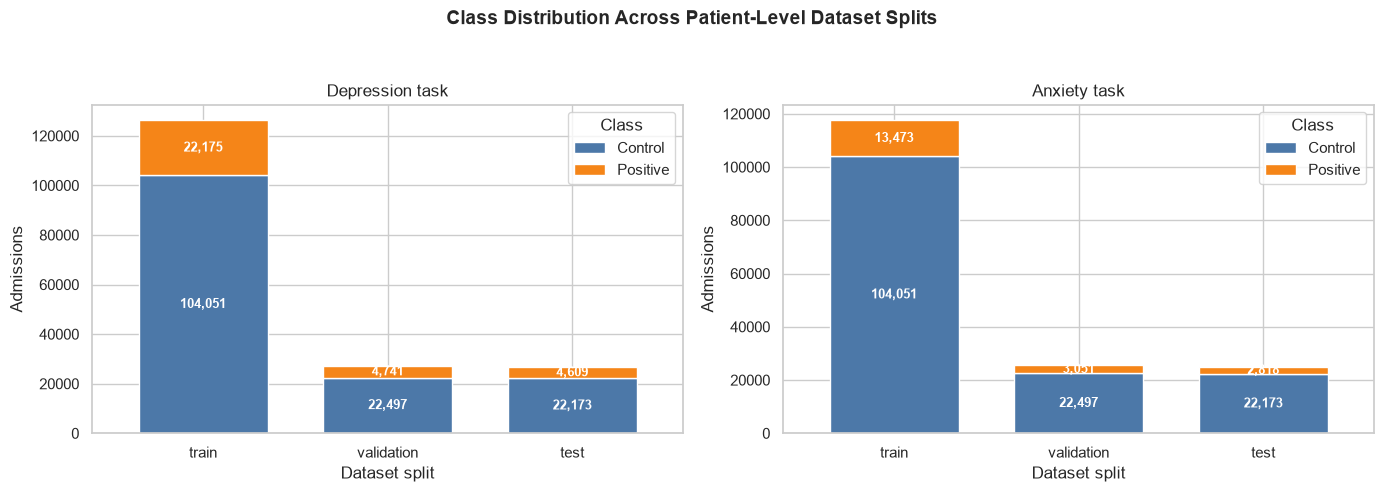

Class-distribution figure saved to: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/model_datasets/audit_outputs/class_distribution_by_split.png


In [32]:
# ============================================================
# CELL 11A - PLOT CLASS COUNTS BY TASK AND SPLIT
# ============================================================

split_order = [
    split_name
    for split_name in [
        "train",
        "validation",
        "test",
    ]
    if split_name in set(task_distribution["split"])
]


task_order = [
    task_name
    for task_name in [
        "depression",
        "anxiety",
    ]
    if task_name in set(task_distribution["task"])
]


class_colors = {
    "control": "#4C78A8",
    "positive": "#F58518",
}


figure, axes = plt.subplots(
    nrows=1,
    ncols=len(task_order),
    figsize=(
        14,
        5,
    ),
    squeeze=False,
)


for axis, task_name in zip(
    axes.ravel(),
    task_order,
):
    task_plot_data = (
        task_distribution.loc[
            task_distribution["task"].eq(task_name)
        ]
        .pivot_table(
            index="split",
            columns="class_name",
            values="admissions",
            aggfunc="sum",
            fill_value=0,
        )
        .reindex(
            index=split_order,
            columns=[
                "control",
                "positive",
            ],
            fill_value=0,
        )
    )


    task_plot_data.plot(
        kind="bar",
        stacked=True,
        ax=axis,
        color=[
            class_colors["control"],
            class_colors["positive"],
        ],
        width=0.70,
    )


    for container in axis.containers:
        segment_labels = [
            f"{int(value):,}"
            if value > 0
            else ""
            for value in container.datavalues
        ]

        axis.bar_label(
            container,
            labels=segment_labels,
            label_type="center",
            fontsize=9,
            color="white",
            fontweight="bold",
        )


    axis.set_title(
        f"{task_name.title()} task"
    )
    axis.set_xlabel("Dataset split")
    axis.set_ylabel("Admissions")
    axis.tick_params(
        axis="x",
        rotation=0,
    )
    axis.legend(
        title="Class",
        labels=[
            "Control",
            "Positive",
        ],
    )


figure.suptitle(
    "Class Distribution Across Patient-Level Dataset Splits",
    fontsize=14,
    fontweight="bold",
)


figure.tight_layout(
    rect=[
        0,
        0,
        1,
        0.94,
    ]
)


class_distribution_figure_path = (
    AUDIT_DIR
    / "class_distribution_by_split.png"
)


figure.savefig(
    class_distribution_figure_path,
    dpi=300,
    bbox_inches="tight",
)


plt.show()


print(
    "Class-distribution figure saved to:",
    class_distribution_figure_path,
)


## 11.2 Visualise positive-class percentages

Counts are strongly affected by dataset size. This second chart compares the
percentage of positive admissions within each task and split, making it easier
to check whether class prevalence is reasonably consistent across the fixed
patient splits.


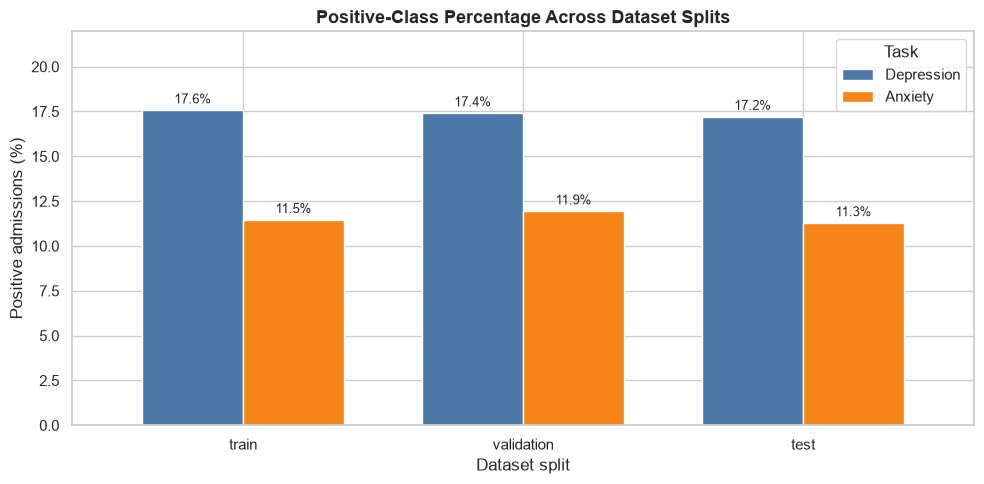

Positive-percentage figure saved to: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/model_datasets/audit_outputs/positive_percentage_by_split.png


In [33]:
# ============================================================
# CELL 11B - PLOT POSITIVE-CLASS PERCENTAGES
# ============================================================

positive_percentage = (
    task_distribution.loc[
        task_distribution["label"].eq(1),
        [
            "task",
            "split",
            "percentage_within_task_split",
        ],
    ]
    .pivot_table(
        index="split",
        columns="task",
        values="percentage_within_task_split",
        aggfunc="first",
    )
    .reindex(
        index=split_order,
        columns=task_order,
    )
)


axis = positive_percentage.plot(
    kind="bar",
    figsize=(
        10,
        5,
    ),
    color=[
        "#4C78A8",
        "#F58518",
    ][:len(task_order)],
    width=0.72,
)


for container in axis.containers:
    percentage_labels = [
        f"{value:.1f}%"
        if pd.notna(value)
        else ""
        for value in container.datavalues
    ]

    axis.bar_label(
        container,
        labels=percentage_labels,
        padding=3,
        fontsize=9,
    )


maximum_percentage = np.nanmax(
    positive_percentage.to_numpy(
        dtype=float
    )
)


axis.set_ylim(
    0,
    max(
        5,
        maximum_percentage * 1.25,
    ),
)


axis.set_title(
    "Positive-Class Percentage Across Dataset Splits",
    fontsize=13,
    fontweight="bold",
)
axis.set_xlabel("Dataset split")
axis.set_ylabel("Positive admissions (%)")
axis.tick_params(
    axis="x",
    rotation=0,
)
axis.legend(
    title="Task",
    labels=[
        task_name.title()
        for task_name in task_order
    ],
)


plt.tight_layout()


positive_percentage_figure_path = (
    AUDIT_DIR
    / "positive_percentage_by_split.png"
)


plt.savefig(
    positive_percentage_figure_path,
    dpi=300,
    bbox_inches="tight",
)


plt.show()


print(
    "Positive-percentage figure saved to:",
    positive_percentage_figure_path,
)


## 12. Review explicit-term leakage

This table reports direct condition terms before masking. A positive note with
an explicit condition term can make classification artificially easy, while an
explicit term in a control note may indicate negation, historical discussion,
family history or label noise.


In [34]:
# ============================================================
# CELL 12 - DISPLAY LEAKAGE SUMMARY
# ============================================================

leakage_summary = leakage_summary.sort_values(
    [
        "task",
        "split",
        "label",
    ],
    ignore_index=True,
)


leakage_summary["class_name"] = leakage_summary["label"].map(
    {
        0: "control",
        1: "positive",
    }
)


display(
    leakage_summary[
        [
            "task",
            "split",
            "label",
            "class_name",
            "admissions",
            "notes_with_explicit_term",
            "pct_with_explicit_term",
            "total_explicit_mentions",
        ]
    ]
)


,task,split,label,class_name,admissions,notes_with_explicit_term,pct_with_explicit_term,total_explicit_mentions
0,anxiety,test,0,control,22173,1602,7.23,2363
1,anxiety,test,1,positive,2818,1571,55.75,3340
2,anxiety,train,0,control,104051,7874,7.57,11738
3,anxiety,train,1,positive,13473,7547,56.02,15638
4,anxiety,validation,0,control,22497,1711,7.61,2524
5,anxiety,validation,1,positive,3051,1778,58.28,3684
6,depression,test,0,control,22173,1318,5.94,1777
7,depression,test,1,positive,4609,1634,35.45,2835
8,depression,train,0,control,104051,6362,6.11,8416
9,depression,train,1,positive,22175,7708,34.76,12715


## 13. Validate patient separation inside each task

Task membership differs, but the fixed patient assignment must remain intact.
No patient may appear in more than one split within the same task.


In [35]:
# ============================================================
# CELL 13 - VALIDATE TASK PATIENT SPLITS
# ============================================================

for task_name in TASK_DEFINITIONS:
    task_patient_groups = {
        split_name: set(
            cohort_metadata.loc[
                (
                    TASK_DEFINITIONS[task_name]["membership_function"](
                        cohort_metadata
                    )
                )
                & cohort_metadata["split"].eq(split_name),
                "subject_id",
            ]
        )
        for split_name in [
            "train",
            "validation",
            "test",
        ]
    }


    train_validation_overlap = (
        task_patient_groups["train"]
        & task_patient_groups["validation"]
    )
    train_test_overlap = (
        task_patient_groups["train"]
        & task_patient_groups["test"]
    )
    validation_test_overlap = (
        task_patient_groups["validation"]
        & task_patient_groups["test"]
    )


    if (
        train_validation_overlap
        or train_test_overlap
        or validation_test_overlap
    ):
        raise ValueError(
            f"Patient overlap detected in the {task_name} task."
        )


    print(
        f"{task_name.title()}: no patient overlap between splits."
    )


Depression: no patient overlap between splits.
Anxiety: no patient overlap between splits.


## 14. Validate saved Parquet files safely

Only Parquet metadata and the first few rows are read. The complete text files
are not reloaded solely for validation.


In [36]:
# ============================================================
# CELL 14 - VALIDATE OUTPUT FILES
# ============================================================

expected_output_keys = [
    "depression",
    "anxiety",
]


if SAVE_MASKED_VARIANTS:
    expected_output_keys.extend(
        [
            "depression_masked",
            "anxiety_masked",
        ]
    )


output_validation_rows = []


for output_key in expected_output_keys:
    output_path = task_output_paths[output_key]

    if not output_path.exists():
        raise FileNotFoundError(
            f"Expected output was not created: {output_path}"
        )


    parquet_file = pq.ParquetFile(output_path)

    output_validation_rows.append(
        {
            "dataset": output_key,
            "rows": parquet_file.metadata.num_rows,
            "row_groups": parquet_file.metadata.num_row_groups,
            "columns": parquet_file.metadata.num_columns,
            "size_mb": round(
                output_path.stat().st_size / (1024 ** 2),
                3,
            ),
            "path": output_path,
        }
    )


    first_batch = next(
        parquet_file.iter_batches(
            batch_size=5,
        )
    )
    preview = first_batch.to_pandas()


    if preview["text"].isna().any():
        raise ValueError(
            f"Missing text detected in {output_key}."
        )


    if not set(preview["label"].unique()).issubset({0, 1}):
        raise ValueError(
            f"Unexpected label detected in {output_key}."
        )


    parquet_file.close()


output_validation_summary = pd.DataFrame(output_validation_rows)


display(output_validation_summary)


print("All task output files passed initial validation.")


,dataset,rows,row_groups,columns,size_mb,path
0,depression,180246,96,12,341.259,/Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/m...
1,anxiety,168063,96,12,316.042,/Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/m...
2,depression_masked,180246,96,12,341.098,/Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/m...
3,anxiety_masked,168063,96,12,315.943,/Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/m...


All task output files passed initial validation.


## 15. Preview unmasked and masked text locally

This preview is for local verification only. Do not copy clinical note text
into GitHub issues, reports or other unauthorised systems.


In [37]:
# ============================================================
# CELL 15 - PREVIEW MASKING
# ============================================================

if SAVE_MASKED_VARIANTS:
    unmasked_file = pq.ParquetFile(
        task_output_paths["depression"]
    )
    masked_file = pq.ParquetFile(
        task_output_paths["depression_masked"]
    )


    unmasked_preview = next(
        unmasked_file.iter_batches(
            batch_size=20,
            columns=["hadm_id", "text"],
        )
    ).to_pandas()


    masked_preview = next(
        masked_file.iter_batches(
            batch_size=20,
            columns=["hadm_id", "text"],
        )
    ).to_pandas()


    comparison = unmasked_preview.merge(
        masked_preview,
        on="hadm_id",
        suffixes=("_unmasked", "_masked"),
        validate="one_to_one",
    )


    changed_rows = comparison.loc[
        comparison["text_unmasked"]
        != comparison["text_masked"]
    ].copy()


    if changed_rows.empty:
        print(
            "No explicit condition terms occurred in the first 20 "
            "depression-task notes. The complete leakage summary above "
            "still covers all notes."
        )
    else:
        changed_rows["unmasked_excerpt"] = (
            changed_rows["text_unmasked"].str[:500]
        )
        changed_rows["masked_excerpt"] = (
            changed_rows["text_masked"].str[:500]
        )


        display(
            changed_rows[
                [
                    "hadm_id",
                    "unmasked_excerpt",
                    "masked_excerpt",
                ]
            ].head(3)
        )


    unmasked_file.close()
    masked_file.close()
else:
    print("Masked variants were not requested.")


,hadm_id,unmasked_excerpt,masked_excerpt
4,24947999,past medical history: - hypertension \n- diabetes \n- hx CVA (cerebellar-medullary stroke in [DEID] \n- CAD (hx of M...,past medical history: - hypertension \n- diabetes \n- hx CVA (cerebellar-medullary stroke in [DEID] \n- CAD (hx of M...
14,27012892,past medical history: - Hypertension \n - s/p lap chole \n - s/p left knee replacement \n - s/p laminectomy of L5-S1...,past medical history: - Hypertension \n - s/p lap chole \n - s/p left knee replacement \n - s/p laminectomy of L5-S1...


## 16. Save aggregate audit files and preprocessing manifest


In [38]:
# ============================================================
# CELL 16 - SAVE AUDIT OUTPUTS AND MANIFEST
# ============================================================

audit_summary.to_csv(
    AUDIT_DIR / "preprocessing_audit_summary.csv",
    index=False,
)


task_distribution.to_csv(
    AUDIT_DIR / "task_split_distribution.csv",
    index=False,
)


task_patient_summary.to_csv(
    AUDIT_DIR / "task_patient_distribution.csv",
    index=False,
)


leakage_summary.to_csv(
    AUDIT_DIR / "explicit_term_leakage_summary.csv",
    index=False,
)


label_combination_summary.to_csv(
    AUDIT_DIR / "master_label_combination_summary.csv",
    index=False,
)


duplicate_audit_path = (
    AUDIT_DIR
    / "duplicate_text_audit.csv"
)


if duplicate_text_audit.empty:
    pd.DataFrame(
        columns=[
            "text_hash",
            "first_hadm_id",
            "duplicate_hadm_id",
            "first_subject_id",
            "duplicate_subject_id",
            "first_split",
            "duplicate_split",
            "crosses_split",
        ]
    ).to_csv(
        duplicate_audit_path,
        index=False,
    )
else:
    duplicate_text_audit.to_csv(
        duplicate_audit_path,
        index=False,
    )


manifest = {
    "source_cohort": str(COHORT_PATH),
    "source_splits": str(SPLITS_PATH),
    "minimum_age": MINIMUM_AGE,
    "minimum_words_for_short_flag": MINIMUM_WORDS_FOR_SHORT_FLAG,
    "drop_short_notes": DROP_SHORT_NOTES,
    "mask_replacement": MASK_REPLACEMENT,
    "masked_variants_saved": SAVE_MASKED_VARIANTS,
    "control_definition": (
        "Admissions negative for both depression and anxiety"
    ),
    "depression_positive_definition": (
        "depression=1, including depression+anxiety comorbidity"
    ),
    "anxiety_positive_definition": (
        "anxiety=1, including depression+anxiety comorbidity"
    ),
    "split_policy": (
        "Fixed patient-level splits inherited from Notebook 02"
    ),
    "tokenization": (
        "Not performed; deferred to model-specific notebooks"
    ),
    "output_files": {
        key: str(path)
        for key, path in task_output_paths.items()
        if path.exists()
    },
    "audit_counts": {
        key: int(value)
        for key, value in audit_counts.items()
    },
}


(AUDIT_DIR / "preprocessing_manifest.json").write_text(
    json.dumps(
        manifest,
        indent=2,
    )
)


print("Audit files and preprocessing manifest were saved to:")
print(AUDIT_DIR)


Audit files and preprocessing manifest were saved to:
/Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/model_datasets/audit_outputs


## 17. Final completion summary

After this notebook completes, the task datasets contain readable clinical
text, binary labels and fixed patient splits. They are ready to be consumed by
the model notebooks, but they are not yet tokenised.

The next notebook is `04_clinicalbert_baseline.ipynb`, which will apply the
ClinicalBERT tokenizer, create overlapping 512-token chunks, train using the
training split and tune using the validation split.


In [39]:
# ============================================================
# CELL 17 - FINAL COMPLETION SUMMARY
# ============================================================

print("Notebook 03 completed successfully.")
print()
print("Model-independent task datasets:")


for output_key, output_path in task_output_paths.items():
    if output_path.exists():
        print(f"- {output_key}: {output_path}")


print()
print("Important next step:")
print(
    "Use each model's own tokenizer in its model-specific notebook."
)
print(
    "Do not regenerate or reshuffle the patient splits."
)


Notebook 03 completed successfully.

Model-independent task datasets:
- depression: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/model_datasets/depression_dataset.parquet
- depression_masked: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/model_datasets/depression_dataset_masked.parquet
- anxiety: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/model_datasets/anxiety_dataset.parquet
- anxiety_masked: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/model_datasets/anxiety_dataset_masked.parquet

Important next step:
Use each model's own tokenizer in its model-specific notebook.
Do not regenerate or reshuffle the patient splits.


## 18. Display the first five records from every task dataset

This final check reads only five rows from each Parquet output. Pandas shortens
long clinical text for display; the saved text is not truncated or modified.


In [40]:
# ============================================================
# CELL 18 - DISPLAY FIRST FIVE RECORDS FROM ALL TASK OUTPUTS
# ============================================================

preview_output_keys = [
    "depression",
    "anxiety",
]


if SAVE_MASKED_VARIANTS:
    preview_output_keys.extend(
        [
            "depression_masked",
            "anxiety_masked",
        ]
    )


for output_key in preview_output_keys:
    output_path = task_output_paths[
        output_key
    ]


    if not output_path.exists():
        print(
            f"Skipping {output_key}: "
            f"file not found at {output_path}"
        )
        continue


    parquet_file = pq.ParquetFile(
        output_path
    )


    first_five_records = next(
        parquet_file.iter_batches(
            batch_size=5,
        )
    ).to_pandas()


    print(
        "\n"
        + "=" * 80
    )
    print(
        f"DATASET: {output_key}"
    )
    print(
        f"FILE: {output_path.name}"
    )
    print(
        f"TOTAL RECORDS: "
        f"{parquet_file.metadata.num_rows:,}"
    )
    print(
        "=" * 80
    )


    display(
        first_five_records
    )


    parquet_file.close()


print(
    "\nFinished displaying the first five records "
    "from every task output dataset."
)



DATASET: depression
FILE: depression_dataset.parquet
TOTAL RECORDS: 180,246


,hadm_id,subject_id,age_at_admission,gender,depression,anxiety,label,split,n_tokens,character_count,word_count,text
0,23052089,10000084,72,M,0,0,0,train,178,848,127,past medical history: [DEID] disease\n[DEID] Body Dementia \ndyslipidemia \nprostate cancer (s/p prostatectomy)\n\nc...
1,27897940,10000764,86,M,0,0,0,train,1187,5572,848,past medical history: MI after AAA repair when he was [DEID] y/o\nHTN\nHypercholesterolemia\n\nchief complaint: Epis...
2,29654838,10000980,75,F,0,0,0,test,1278,5646,913,"past medical history: 1. CAD RISK FACTORS: +Diabetes, +Dyslipidemia, +Hypertension\n2. CARDIAC HISTORY: \nMI in [DEI..."
3,26913865,10000980,76,F,0,0,0,test,928,4257,663,past medical history: - hypertension\n- diabetes\n- hx CVA (cerebellar-medullary stroke in [DEID]\n- CAD (has never ...
4,24947999,10000980,77,F,0,0,0,test,1578,6947,1127,past medical history: - hypertension \n- diabetes \n- hx CVA (cerebellar-medullary stroke in [DEID] \n- CAD (hx of M...



DATASET: anxiety
FILE: anxiety_dataset.parquet
TOTAL RECORDS: 168,063


,hadm_id,subject_id,age_at_admission,gender,depression,anxiety,label,split,n_tokens,character_count,word_count,text
0,23052089,10000084,72,M,0,0,0,train,178,848,127,past medical history: [DEID] disease\n[DEID] Body Dementia \ndyslipidemia \nprostate cancer (s/p prostatectomy)\n\nc...
1,27897940,10000764,86,M,0,0,0,train,1187,5572,848,past medical history: MI after AAA repair when he was [DEID] y/o\nHTN\nHypercholesterolemia\n\nchief complaint: Epis...
2,29654838,10000980,75,F,0,0,0,test,1278,5646,913,"past medical history: 1. CAD RISK FACTORS: +Diabetes, +Dyslipidemia, +Hypertension\n2. CARDIAC HISTORY: \nMI in [DEI..."
3,26913865,10000980,76,F,0,0,0,test,928,4257,663,past medical history: - hypertension\n- diabetes\n- hx CVA (cerebellar-medullary stroke in [DEID]\n- CAD (has never ...
4,24947999,10000980,77,F,0,0,0,test,1578,6947,1127,past medical history: - hypertension \n- diabetes \n- hx CVA (cerebellar-medullary stroke in [DEID] \n- CAD (hx of M...



DATASET: depression_masked
FILE: depression_dataset_masked.parquet
TOTAL RECORDS: 180,246


,hadm_id,subject_id,age_at_admission,gender,depression,anxiety,label,split,n_tokens,character_count,word_count,text
0,23052089,10000084,72,M,0,0,0,train,178,848,127,past medical history: [DEID] disease\n[DEID] Body Dementia \ndyslipidemia \nprostate cancer (s/p prostatectomy)\n\nc...
1,27897940,10000764,86,M,0,0,0,train,1187,5572,848,past medical history: MI after AAA repair when he was [DEID] y/o\nHTN\nHypercholesterolemia\n\nchief complaint: Epis...
2,29654838,10000980,75,F,0,0,0,test,1278,5646,913,"past medical history: 1. CAD RISK FACTORS: +Diabetes, +Dyslipidemia, +Hypertension\n2. CARDIAC HISTORY: \nMI in [DEI..."
3,26913865,10000980,76,F,0,0,0,test,928,4257,663,past medical history: - hypertension\n- diabetes\n- hx CVA (cerebellar-medullary stroke in [DEID]\n- CAD (has never ...
4,24947999,10000980,77,F,0,0,0,test,1578,6947,1127,past medical history: - hypertension \n- diabetes \n- hx CVA (cerebellar-medullary stroke in [DEID] \n- CAD (hx of M...



DATASET: anxiety_masked
FILE: anxiety_dataset_masked.parquet
TOTAL RECORDS: 168,063


,hadm_id,subject_id,age_at_admission,gender,depression,anxiety,label,split,n_tokens,character_count,word_count,text
0,23052089,10000084,72,M,0,0,0,train,178,848,127,past medical history: [DEID] disease\n[DEID] Body Dementia \ndyslipidemia \nprostate cancer (s/p prostatectomy)\n\nc...
1,27897940,10000764,86,M,0,0,0,train,1187,5572,848,past medical history: MI after AAA repair when he was [DEID] y/o\nHTN\nHypercholesterolemia\n\nchief complaint: Epis...
2,29654838,10000980,75,F,0,0,0,test,1278,5646,913,"past medical history: 1. CAD RISK FACTORS: +Diabetes, +Dyslipidemia, +Hypertension\n2. CARDIAC HISTORY: \nMI in [DEI..."
3,26913865,10000980,76,F,0,0,0,test,928,4257,663,past medical history: - hypertension\n- diabetes\n- hx CVA (cerebellar-medullary stroke in [DEID]\n- CAD (has never ...
4,24947999,10000980,77,F,0,0,0,test,1578,6947,1127,past medical history: - hypertension \n- diabetes \n- hx CVA (cerebellar-medullary stroke in [DEID] \n- CAD (hx of M...



Finished displaying the first five records from every task output dataset.
